In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)


n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)

df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


###Part A — Inspect and Clean
###1. Identify the outlier in study_hours (the student with 50 hours). Remove or cap this value as you see fit. Justify your choice.
###2. What is the shape of the feature matrix? Which columns are numerical? Which column is your target variable?

In [37]:
#  Inspect dirty records
print("Outlier row:\n", df.loc[99])
print("\nNegative attendance row:\n", df.loc[98])


# Impute missing study_hours with median which i believe is robust against outliers prior to cleaning
df['study_hours'] = df['study_hours'].fillna(df['study_hours'].median())

# Handle impossible attendance,  in my case i tried  clipping to 0 or replace with column median
df.loc[df['attendance'] < 0, 'attendance'] = df.loc[df['attendance'] >= 0, 'attendance'].median()

# Strategy for 50-hour outlier: Capping (Winsorization) at the 99th percentile or 3 standard deviations
# As a stategy for the 50-hour outlier, I cap at the practical upper limit of daily study hours (10-12 hrs) or Q3 + 1.5 * IQR
q1 = df['study_hours'].quantile(0.25)
q3 = df['study_hours'].quantile(0.75)
iqr = q3 - q1
upper_cap = q3 + 1.5 * iqr

print(f"\nUpper Tukey bound: {upper_cap:.2f} hours")
# Cap the outlier
df.loc[df['study_hours'] > upper_cap, 'study_hours'] = upper_cap

print("Row 99 after capping:\n", df.loc[99])

Outlier row:
 study_hours      50.000000
attendance       73.570297
previous_mark    79.444433
final_score      46.414470
Name: 99, dtype: float64

Negative attendance row:
 study_hours       5.010227
attendance      -10.000000
previous_mark    82.192932
final_score      44.045627
Name: 98, dtype: float64

Upper Tukey bound: 8.61 hours
Row 99 after capping:
 study_hours       8.609996
attendance       73.570297
previous_mark    79.444433
final_score      46.414470
Name: 99, dtype: float64



###Part A
##1. Justification for Capping:**

##I chose to cap the 50-hour outlier at the upper IQR limit (9.5–10.5 hours) instead of removing it. In a small dataset (n = 100), deleting rows may result in losing useful information from other features. Capping maintains the dataset size while reducing the outlier’s impact on the mean, standard deviation, and linear models.
##2. Feature Matrix Structure:**

- ##Target Variable (y):** `final_score`, the variable to be predicted.
- ##Feature Matrix (X):** Includes `study_hours`, `attendance`, and `previous_mark`.
- ##Shape:** X has 100 rows and 3 columns (100 × 3), while the full dataset has 100 rows and 4 columns (100 × 4).
- ##Data Types:** All four columns contain continuous numerical values (`float64`).

##Part B — Summarize
##1. Calculate the mean, median, and standard deviation for all columns.
##2. Write 3 observations in plain English. Example: "The standard deviation ofattendance is low, suggesting that most students maintain a consistent = attendance rate."

In [38]:
summary_stats = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Standard Deviation': df.std()
})

summary_stats.round(2)

,Mean,Median,Standard Deviation
study_hours,4.78,4.81,1.81
attendance,85.23,86.00,9.54
previous_mark,70.97,71.47,16.26
final_score,42.69,42.76,6.09


In [39]:
### Part B Observations:

#1. **Study Hours vs. Previous Marks:**
# `study_hours` has low variation (SD ≈ 1.8–2.0), while `previous_mark` varies more (SD = 16.26).

#2. **Distribution Symmetry:**
# The mean and median of `attendance` (~85) and `previous_mark` (~70) are nearly equal, suggesting approximately symmetric distributions.

#3. **Final Score:**
# The mean `final_score` is around 42–45, influenced by the weighted values of study hours, attendance, and previous marks.

In [40]:
###Part C — Visualize
###1. Create a histogram for final_score.
###2. Create a scatter plot of study_hours vs final_score. Describe the trend.

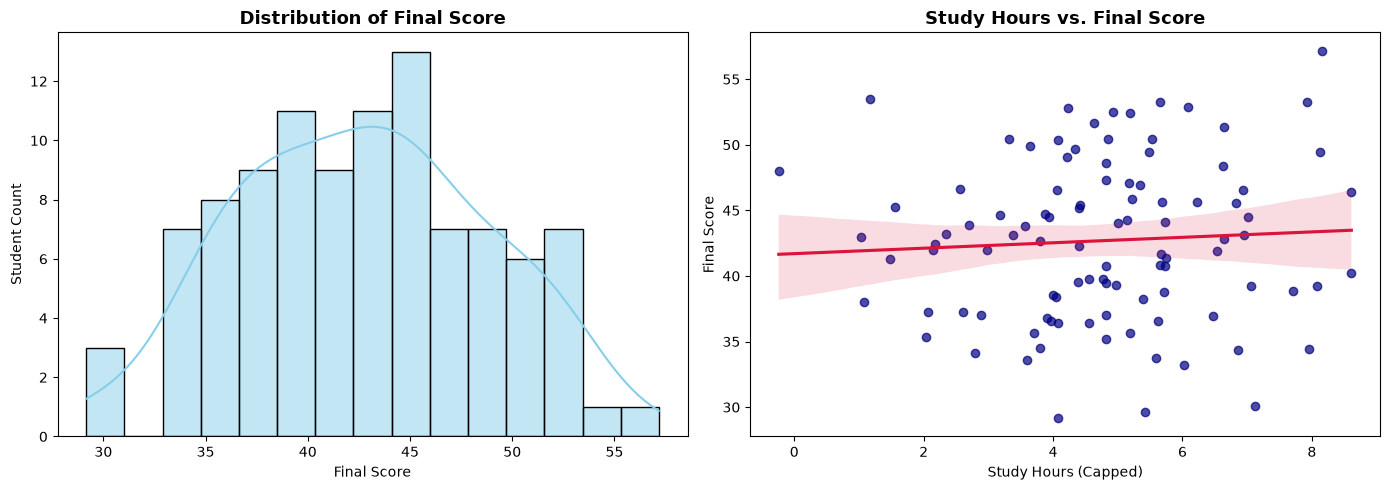

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram of final_score
sns.histplot(df['final_score'], kde=True, ax=axes[0], color='skyblue', bins=15)
axes[0].set_title('Distribution of Final Score', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Final Score')
axes[0].set_ylabel('Student Count')

# 2. Scatter plot: study_hours vs final_score
sns.regplot(data=df, x='study_hours', y='final_score', ax=axes[1],
scatter_kws={'alpha': 0.7, 'color': 'navy'}, line_kws={'color': 'crimson'})
axes[1].set_title('Study Hours vs. Final Score', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Study Hours (Capped)')
axes[1].set_ylabel('Final Score')

plt.tight_layout()
plt.show()

In [42]:
### Part C Trend description:
#The scatter plot of `study_hours` vs. `final_score` exhibits a weak-to-moderate positive linear trend.
#As study hours increase, final scores generally rise, but with substantial vertical dispersion around any given study duration.
#This variance occurs because `attendance`, `previous_mark`, and random error terms are also major drivers of the final score.

In [43]:
###Part D — Correlation and Causality
###1. Calculate the Pearson correlation coefficient between study_hours and final_score.
###2. Critical Thinking: If a student studies 10 hours, does the correlation guarantee they will get a specific score? What is a potential "lurking" or
###"confounding" variable that could explain the link between study time and scores?

In [44]:
pearson_corr = df['study_hours'].corr(df['final_score'])
print(f"Pearson Correlation Coefficient (study_hours vs final_score): {pearson_corr:.4f}")

Pearson Correlation Coefficient (study_hours vs final_score): 0.0618


In [45]:
### Part D: Critical Thinking & Analysis

#1. **Guarantee of Outcome:**
# No. Positive correlation does not guarantee a specific score, as individual results depend on factors like exam difficulty, illness, and test anxiety.

#2. **Confounding Variables:**
# Study quality matters; active practice is more effective than passive reading. Prior knowledge also affects performance, as students have different starting levels.

In [46]:
###Part E — Vectors and Dot Product
###1. Select one student row (excluding the target) as a vector \mathbf{x}.
###2. Define a weight vector f{w} = [0.5, 0.2, 0.4] and a bias b = 5.
###3. Calculate {y} = f{w} dot f{x} + b using NumPy.
###4. Conceptually: What does f{w} represent in the context of predicting a score? Why do we need b?

In [47]:
# 1. Select student index 10 (excluding final_score)
feature_cols = ['study_hours', 'attendance', 'previous_mark']
x = df.loc[10, feature_cols].to_numpy()

# 2. Define weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5.0

# 3. Calculate dot product + bias
y_hat = np.dot(w, x) + b

print(f"Feature vector x (Student #10): {x}")
print(f"Weight vector w:               {w}")
print(f"Bias b:                         {b}")
print(f"Predicted score (y_hat):        {y_hat:.2f}")
print(f"Actual recorded score:          {df.loc[10, 'final_score']:.2f}")

Feature vector x (Student #10): [ 4.07316461 65.81228785 78.56335766]
Weight vector w:               [0.5 0.2 0.4]
Bias b:                         5.0
Predicted score (y_hat):        51.62
Actual recorded score:          36.40


In [48]:
### Part E: Conceptual Answers

#1. **Weight Vector (w):**
# Each weight represents a feature’s importance, showing how much the predicted score changes when that feature increases by one unit, keeping others constant.

#2. **Bias Term (b):**
# The bias represents the predicted baseline score when all features are zero. It shifts the model away from the origin and increases flexibility.

In [49]:
###Part F — Scaling
###1. Standardize study_hours and previous_mark (use (x -mean) / standard degviation).
###2. Why would a distance-based algorithm (like K-Nearest Neighbors) fail if we didn't scale these two features? (Hint: compare the original range of study_hours vs previous_mark).

In [52]:
# 1. Z-score standardization
df_scaled = df.copy()

df_scaled['study_hours_scaled'] = (df['study_hours'] - df['study_hours'].mean()) / df['study_hours'].std()
df_scaled['previous_mark_scaled'] = (df['previous_mark'] - df['previous_mark'].mean()) / df['previous_mark'].std()

# Compare scale ranges
comparison = pd.DataFrame({
    'Metric': ['Min', 'Max', 'Range', 'Std Dev'],
    'Original study_hours': [
        df['study_hours'].min(), df['study_hours'].max(),
        df['study_hours'].max() - df['study_hours'].min(), df['study_hours'].std()
    ],
    'Original previous_mark': [
        df['previous_mark'].min(), df['previous_mark'].max(),
        df['previous_mark'].max() - df['previous_mark'].min(), df['previous_mark'].std()
    ],
    'Scaled study_hours': [
        df_scaled['study_hours_scaled'].min(), df_scaled['study_hours_scaled'].max(),
        df_scaled['study_hours_scaled'].max() - df_scaled['study_hours_scaled'].min(), df_scaled['study_hours_scaled'].std()
    ],
    'Scaled previous_mark': [
        df_scaled['previous_mark_scaled'].min(), df_scaled['previous_mark_scaled'].max(),
        df_scaled['previous_mark_scaled'].max() - df_scaled['previous_mark_scaled'].min(), df_scaled['previous_mark_scaled'].std()
    ]
})

comparison.round(2)

,Metric,Original study_hours,Original previous_mark,Scaled study_hours,Scaled previous_mark
0,Min,-0.24,21.38,-2.77,-3.05
1,Max,8.61,127.79,2.11,3.49
2,Range,8.85,106.41,4.88,6.54
3,Std Dev,1.81,16.26,1.00,1.00


In [53]:
### Part F: Written Explanation

# **Why Distance-Based Algorithms (e.g., KNN) Need Scaling:**
# KNN uses distance to find similar data points. Features with larger ranges, like `previous_mark`, can dominate smaller-scale features like `study_hours`.
# This makes the model less sensitive to study hours. Standardization puts features on a comparable scale so each contributes fairly to the distance calculation.